# Re-Engagement Email Experiment: Should We Ship, and Which Version?

**Author:** Parth Patel
**Stack:** Databricks · PySpark · Python (pandas, scipy, statsmodels)

---

## 1. Business Context
An e-commerce retailer wants to know whether a targeted email campaign increases customer spending in the two weeks after it is sent, and if so, whether a **men's merchandise** or **women's merchandise** email performs better. This notebook analyzes a randomized controlled experiment and ends with a ship / don't-ship recommendation.

## 2. Dataset
**Source:** Kevin Hillstrom, *MineThatData E-Mail Analytics and Data Mining Challenge* (2008)

- **64,000 customers** who purchased within the last 12 months
- Randomly assigned in equal thirds to three arms:
  - `Mens E-Mail` (treatment A)
  - `Womens E-Mail` (treatment B)
  - `No E-Mail` (control)
- Outcomes tracked for **two weeks** after the email

| Column | Description |
|---|---|
| `recency` | Months since last purchase (pre-period) |
| `history` | Dollars spent in the past year (pre-period) |
| `history_segment` | Binned version of `history` |
| `mens` / `womens` | Purchased men's / women's merchandise in past year |
| `zip_code` | Urban / Suburban / Rural |
| `newbie` | New customer in the past 12 months |
| `channel` | Purchase channel in past year (Phone / Web / Multichannel) |
| `segment` | **Assigned experiment arm** |
| `visit` | Visited the website within 2 weeks (outcome) |
| `conversion` | Purchased within 2 weeks (outcome) |
| `spend` | Dollars spent within 2 weeks (outcome) |

## 3. Experiment Design

**Hypotheses** (each treatment vs. control):
- H₀: Mean spend per customer in treatment = mean spend in control
- H₁: Mean spend per customer in treatment ≠ mean spend in control

**Metrics**
- **Primary:** Spend per customer (revenue per user, including non-buyers)
- **Secondary:** Visit rate, conversion rate
- **Guardrail:** Unsubscribe / complaint rate is not available in the data. It is treated as a qualitative risk in the final memo.

**Parameters**
- Significance level α = 0.05 (two-sided), adjusted for 2 treatment comparisons
- Target power = 0.80
- Minimum detectable effect (MDE): determined in the power analysis section

## 4. Analysis Plan
1. **Data validation and EDA:** schema checks, missing values, distribution of spend (heavily zero-inflated)
2. **Randomization checks:** Sample Ratio Mismatch (SRM) chi-square test and covariate balance across arms
3. **Power analysis:** MDE achievable with the observed sample size
4. **A/A simulation:** confirm the false-positive rate holds near 5%
5. **Treatment effects:** Welch's t-test and bootstrap CIs on spend; two-proportion z-tests on visit and conversion
6. **CUPED variance reduction:** use pre-period `history` as the covariate and quantify the variance and sample-size reduction
7. **Peeking simulation:** show error inflation from repeated looks vs. a sequential approach
8. **Segment analysis:** heterogeneous effects by channel, zip code, and newbie status, with Benjamini–Hochberg correction
9. **Decision memo:** recommendation, confidence, risks, and next steps

## 5. Known Limitations
- No guardrail metric (e.g., unsubscribes) is recorded, so long-term cost of email fatigue can't be measured.
- The outcome window is only two weeks, so long-run retention effects are out of scope.
- Spend is zero-inflated and right-skewed, so mean-based tests rely on large-sample approximations. Bootstrap CIs are used as a robustness check.

## 1. Data Validation & EDA
Goal: confirm the data is clean and behaves the way the experiment description says it should, before running any statistical tests.

In [0]:
!pip install statsmodels
!pip install seaborn

In [0]:
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chisquare
import numpy as np
from scipy.stats import norm
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest



In [0]:
#Load

# Download the CSV from the MineThatData blog (see README) and place it in data/
url = 'data/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv'

df = spark.read.csv(url, header=True, inferSchema=True).toPandas()
df.head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [0]:
#Structure

print(df.shape)
df.info()

(64000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int32  
 1   history_segment  64000 non-null  object 
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int32  
 4   womens           64000 non-null  int32  
 5   zip_code         64000 non-null  object 
 6   newbie           64000 non-null  int32  
 7   channel          64000 non-null  object 
 8   segment          64000 non-null  object 
 9   visit            64000 non-null  int32  
 10  conversion       64000 non-null  int32  
 11  spend            64000 non-null  float64
dtypes: float64(2), int32(6), object(4)
memory usage: 4.4+ MB


In [0]:
#Missing values and duplicates

print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64
Duplicates: 6562


In [0]:
#Summary Stats

df.describe()

,recency,history,mens,womens,newbie,visit,conversion,spend
count,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000,64000.000000
mean,5.763734,242.085656,0.551031,0.549719,0.502250,0.146781,0.009031,1.050908
std,3.507592,256.158608,0.497393,0.497526,0.499999,0.353890,0.094604,15.036448
min,1.000000,29.990000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,64.660000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,6.000000,158.110000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
75%,9.000000,325.657500,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
max,12.000000,3345.930000,1.000000,1.000000,1.000000,1.000000,1.000000,499.000000


In [0]:
#Categorical Cols

for c in df.select_dtypes("object").columns:
    print(df[c].value_counts(), "\n")

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64 

zip_code
Surburban    28776
Urban        25661
Rural         9563
Name: count, dtype: int64 

channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64 

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64 



Share with $0 spend: 99.1%


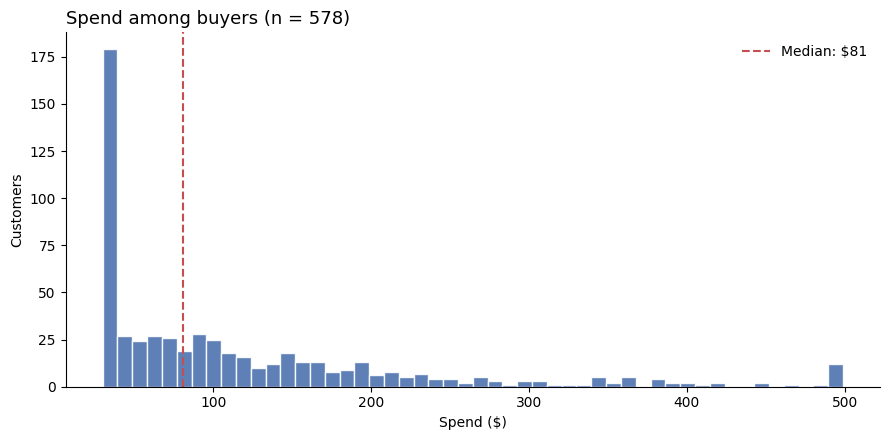

In [0]:
#Spend Distribution

buyers = df.loc[df["spend"] > 0, "spend"]
print(f"Share with $0 spend: {(df['spend'] == 0).mean():.1%}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(buyers, bins=50, color="#4C72B0", edgecolor="white", alpha=0.9)
ax.axvline(buyers.median(), color="#C44E52", linestyle="--", linewidth=1.5,
           label=f"Median: ${buyers.median():.0f}")

ax.set_title(f"Spend among buyers (n = {len(buyers):,})", fontsize=13, loc="left")
ax.set_xlabel("Spend ($)")
ax.set_ylabel("Customers")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [0]:
#Quick look by arm

df.groupby("segment")[["recency", "history", "visit", "conversion", "spend"]].mean()

,recency,history,visit,conversion,spend
segment,,,,,
Mens E-Mail,5.773642,242.835931,0.182757,0.012531,1.422617
No E-Mail,5.749695,240.882653,0.106167,0.005726,0.652789
Womens E-Mail,5.767850,242.536633,0.151400,0.008837,1.077202


### EDA Findings
- **Data quality:** 64,000 rows, 12 columns, no missing values.
- **Duplicates:** 6,562 rows are exact duplicates across all columns. The dataset has no customer ID and 99% of outcomes are zero, so these are identical-looking but distinct customers. **Retained.**
- **Arm sizes:** roughly equal thirds (21,307 / 21,306 / 21,387).
- **Spend distribution:** 99.1% of customers spent $0 in the two-week window; buyer spend is right-skewed (max $499). The primary metric is therefore zero-inflated and high-variance, so Welch's t-test is paired with bootstrap CIs.
- **Note:** the arm-level means above are descriptive only. No conclusions until the tests are run.

## 2. Randomization Checks
### 2a. Sample Ratio Mismatch (SRM)
The experiment was designed with an equal 1/3 split across the three arms. A chi-square goodness-of-fit test checks whether the observed arm sizes are consistent with that design.
- **H₀:** observed arm sizes match the planned 1/3 split
- **H₁:** observed arm sizes differ from the planned split
- **Threshold:** p < 0.001 (industry-standard strict threshold for SRM)

In [0]:
observed = df["segment"].value_counts().sort_index()
expected = [len(df) / 3] * 3

srm = pd.DataFrame({
    "observed": observed,
    "expected": expected,
    "share": (observed / len(df)).round(4)
})
display(srm)

stat, p = chisquare(observed, f_exp=expected)
print(f"Chi-square: {stat:.3f}")
print(f"p-value:    {p:.4f}")
print("SRM detected" if p < 0.001 else "No SRM: arm sizes are consistent with a 1/3 split")

observed,expected,share
21307,21333.333333333332,0.3329
21306,21333.333333333332,0.3329
21387,21333.333333333332,0.3342


Chi-square: 0.203
p-value:    0.9037
No SRM: arm sizes are consistent with a 1/3 split


**Result:** χ² = 0.203, p = 0.904. Arm sizes are consistent with the planned equal split, so there is no evidence of a randomization or logging problem.

### 2b. Covariate Balance
Checks that the three arms had a similar mix of pre-experiment characteristics. Balance is measured with the **standardized mean difference (SMD)** of each email arm vs. control, where **|SMD| < 0.1** is treated as balanced.

`history_segment` is excluded because it's a binned version of `history`.

In [0]:
# Pre-experiment covariates; categoricals become 0/1 columns
covs = pd.get_dummies(
    df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]],
    dtype=float
)

control = covs[df["segment"] == "No E-Mail"]

smd = {}
for arm in ["Mens E-Mail", "Womens E-Mail"]:
    treat = covs[df["segment"] == arm]
    pooled_sd = np.sqrt((treat.var() + control.var()) / 2)
    smd[arm] = (treat.mean() - control.mean()) / pooled_sd

smd = pd.DataFrame(smd).round(3)
display(smd)

print("Max |SMD|:", smd.abs().max().max())
print("Balanced" if (smd.abs() < 0.1).all().all() else "Imbalance found")

Mens E-Mail,Womens E-Mail
0.007,0.005
0.008,0.007
-0.005,-0.009
0.008,0.005
-0.001,0.003
0.014,0.004
-0.012,-0.001
0.002,-0.002
-0.004,-0.005
-0.008,0.009


Max |SMD|: 0.014
Balanced


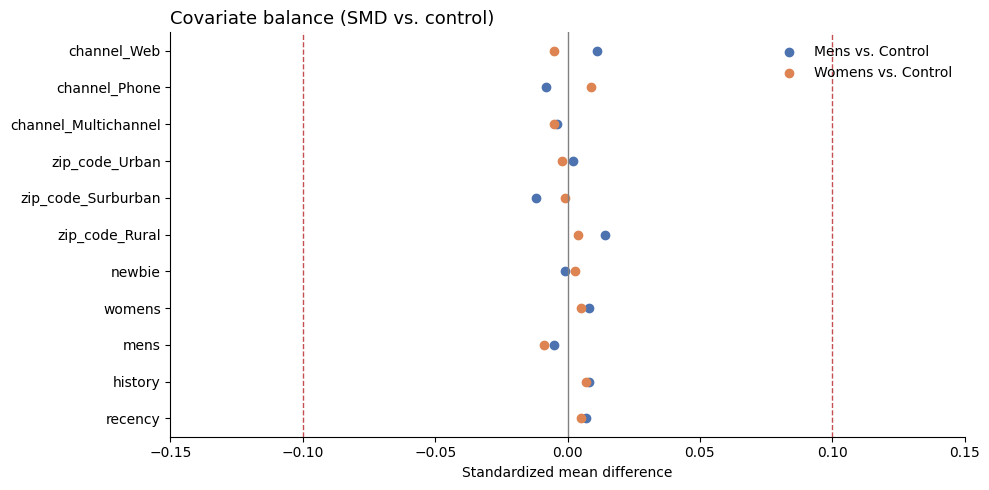

In [0]:
#Balance plot

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(smd["Mens E-Mail"], smd.index, label="Mens vs. Control", color="#4C72B0")
ax.scatter(smd["Womens E-Mail"], smd.index, label="Womens vs. Control", color="#DD8452")

ax.axvline(0, color="grey", linewidth=1)
for x in (-0.1, 0.1):
    ax.axvline(x, color="#C44E52", linestyle="--", linewidth=1)

ax.set_title("Covariate balance (SMD vs. control)", loc="left", fontsize=13)
ax.set_xlabel("Standardized mean difference")
ax.set_xlim(-0.15, 0.15)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

**Result:** All covariates have |SMD| ≤ 0.014, far below the 0.1 threshold. The arms are balanced on pre-experiment characteristics, so post-experiment differences can be attributed to the emails.

## 3. Power Analysis: Minimum Detectable Effect (MDE)
The MDE is the smallest true effect this experiment can reliably detect, given its sample size and each metric's variance.
- **α = 0.025** per comparison (0.05 Bonferroni-adjusted for 2 email-vs-control comparisons), two-sided
- **Power = 0.80**
- σ and baseline come from the control arm

In [0]:
alpha = 0.05 / 2
power = 0.80
z = norm.ppf(1 - alpha / 2) + norm.ppf(power)

control = df[df["segment"] == "No E-Mail"]
n = len(control)

rows = []
for metric in ["spend", "visit", "conversion"]:
    baseline = control[metric].mean()
    sd = control[metric].std()
    mde = z * sd * np.sqrt(2 / n)
    rows.append({
        "metric": metric,
        "baseline": round(baseline, 4),
        "std_dev": round(sd, 4),
        "MDE_absolute": round(mde, 4),
        "MDE_relative": f"{mde / baseline:.1%}"
    })

pd.DataFrame(rows)

,metric,baseline,std_dev,MDE_absolute,MDE_relative
0,spend,0.6528,11.5882,0.3461,53.0%
1,visit,0.1062,0.3081,0.0092,8.7%
2,conversion,0.0057,0.0755,0.0023,39.4%


**Result:** With ~21,300 customers per arm, the experiment can detect:
- Spend per customer: **$0.35** (53% relative)
- Visit rate: **0.92 pp** (8.7% relative)
- Conversion rate: **0.23 pp** (39% relative)

**Takeaway:** spend has a large relative MDE because it's zero-inflated and high-variance, so it's the hardest metric to move detectably. Visit rate is far more sensitive.

## 4. A/A Simulation: Validating the False-Positive Rate
The control arm is randomly split into two halves 1,000 times, and Welch's t-test is run on spend each time. Since both halves received the same experience, any significant result is a false positive.
- **Expected:** ~5% of tests significant at α = 0.05
- With 1,000 simulations, normal random variation puts this between roughly **3.6% and 6.4%**
- p-values should be **uniformly distributed** between 0 and 1

In [0]:
rng = np.random.default_rng(42)
spend = control["spend"].to_numpy()
half = len(spend) // 2

pvals = []
for _ in range(1000):
    idx = rng.permutation(len(spend))
    a, b = spend[idx[:half]], spend[idx[half:]]
    pvals.append(ttest_ind(a, b, equal_var=False).pvalue)

pvals = np.array(pvals)
print(f"False-positive rate: {(pvals < 0.05).mean():.1%}")

False-positive rate: 4.9%


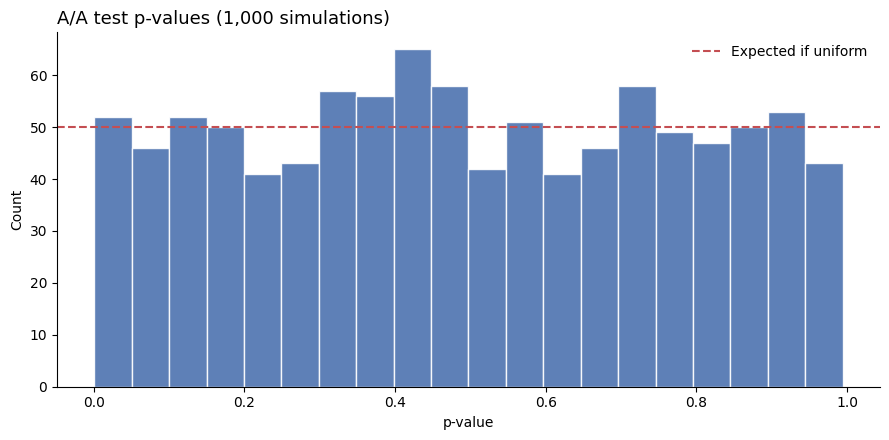

In [0]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(pvals, bins=20, color="#4C72B0", edgecolor="white", alpha=0.9)
ax.axhline(len(pvals) / 20, color="#C44E52", linestyle="--", linewidth=1.5,
           label="Expected if uniform")

ax.set_title("A/A test p-values (1,000 simulations)", loc="left", fontsize=13)
ax.set_xlabel("p-value")
ax.set_ylabel("Count")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

**Result:** The false-positive rate was **4.9%**, within the expected 3.6–6.4% range, and p-values are roughly uniform. Despite 99% zeros, Welch's t-test is well-calibrated on spend at this sample size.

## 5. Treatment Effects
Each email arm is compared against control (No E-Mail).
- **Spend:** Welch's t-test, with a bootstrap CI as a robustness check
- **Visit and conversion:** two-proportion z-test
- **α = 0.025** per comparison (Bonferroni for 2 comparisons), so all CIs are **97.5%**

In [0]:
#Setup

alpha = 0.025
arms = ["Mens E-Mail", "Womens E-Mail"]
control = df[df["segment"] == "No E-Mail"]

#Spend, Welch’s t-test

rows = []
for arm in arms:
    t = df[df["segment"] == arm]["spend"]
    c = control["spend"]

    res = ttest_ind(t, c, equal_var=False)
    ci = res.confidence_interval(confidence_level=1 - alpha)
    lift = t.mean() - c.mean()

    rows.append({
        "arm": arm,
        "control": round(c.mean(), 3),
        "treatment": round(t.mean(), 3),
        "abs_lift": round(lift, 3),
        "rel_lift": f"{lift / c.mean():.1%}",
        "ci_low": round(ci.low, 3),
        "ci_high": round(ci.high, 3),
        "p_value": round(res.pvalue, 5),
    })

spend_results = pd.DataFrame(rows)
spend_results

,arm,control,treatment,abs_lift,rel_lift,ci_low,ci_high,p_value
0,Mens E-Mail,0.653,1.423,0.770,117.9%,0.444,1.095,0.00000
1,Womens E-Mail,0.653,1.077,0.424,65.0%,0.132,0.717,0.00113


In [0]:
rng = np.random.default_rng(42)
c = control["spend"].to_numpy()

rows = []
for arm in arms:
    t = df[df["segment"] == arm]["spend"].to_numpy()

    diffs = np.array([
        rng.choice(t, len(t)).mean() - rng.choice(c, len(c)).mean()
        for _ in range(5000)
    ])
    low, high = np.percentile(diffs, [100 * alpha / 2, 100 * (1 - alpha / 2)])

    rows.append({"arm": arm, "boot_ci_low": round(low, 3), "boot_ci_high": round(high, 3)})

# Side by side with the Welch CI
spend_results.merge(pd.DataFrame(rows), on="arm")[
    ["arm", "abs_lift", "ci_low", "ci_high", "boot_ci_low", "boot_ci_high"]
]

,arm,abs_lift,ci_low,ci_high,boot_ci_low,boot_ci_high
0,Mens E-Mail,0.770,0.444,1.095,0.437,1.087
1,Womens E-Mail,0.424,0.132,0.717,0.137,0.728


In [0]:
z_crit = norm.ppf(1 - alpha / 2)
rows = []

for metric in ["visit", "conversion"]:
    for arm in arms:
        t = df[df["segment"] == arm][metric]
        c = control[metric]

        _, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])

        p1, p0 = t.mean(), c.mean()
        lift = p1 - p0
        se = np.sqrt(p1 * (1 - p1) / len(t) + p0 * (1 - p0) / len(c))

        rows.append({
            "metric": metric,
            "arm": arm,
            "control": f"{p0:.2%}",
            "treatment": f"{p1:.2%}",
            "abs_lift_pp": round(lift * 100, 3),
            "rel_lift": f"{lift / p0:.1%}",
            "ci_low_pp": round((lift - z_crit * se) * 100, 3),
            "ci_high_pp": round((lift + z_crit * se) * 100, 3),
            "p_value": round(p, 5),
        })

pd.DataFrame(rows)

,metric,arm,control,treatment,abs_lift_pp,rel_lift,ci_low_pp,ci_high_pp,p_value
0,visit,Mens E-Mail,10.62%,18.28%,7.659,72.1%,6.900,8.418,0.00000
1,visit,Womens E-Mail,10.62%,15.14%,4.523,42.6%,3.798,5.248,0.00000
2,conversion,Mens E-Mail,0.57%,1.25%,0.681,118.8%,0.474,0.887,0.00000
3,conversion,Womens E-Mail,0.57%,0.88%,0.311,54.3%,0.127,0.495,0.00016


### Results (each email vs. control)
| Metric | Control | Men's email | Women's email |
|---|---|---|---|
| Spend per customer | $0.65 | **+$0.77 (+118%)**, 97.5% CI [0.44, 1.10], p < 0.001 | **+$0.42 (+65%)**, 97.5% CI [0.13, 0.72], p = 0.001 |
| Visit rate | 10.6% | **+7.7 pp (+72%)**, CI [6.9, 8.4], p < 0.001 | **+4.5 pp (+43%)**, CI [3.8, 5.2], p < 0.001 |
| Conversion rate | 0.57% | **+0.68 pp (+119%)**, CI [0.47, 0.89], p < 0.001 | **+0.31 pp (+54%)**, CI [0.13, 0.50], p < 0.001 |

- **Bootstrap check:** bootstrap CIs for spend closely match the Welch CIs (Men's [0.44, 1.09] vs. [0.44, 1.10]; Women's [0.14, 0.73] vs. [0.13, 0.72]), so the result isn't driven by the skewed distribution.
- **Interpretation:** both emails significantly increased all three metrics at the Bonferroni-adjusted α = 0.025, and both spend lifts exceed the $0.35 MDE.

## 6. CUPED Variance Reduction
CUPED (Controlled-experiment Using Pre-Experiment Data) reduces metric variance by adjusting each customer's spend using their pre-period spend (`history`):

Y_cuped = Y − θ(X − mean(X)), where θ = Cov(X, Y) / Var(X)

- `history` is measured before randomization, so it's unaffected by treatment and the lift estimate stays unbiased
- Expected variance reduction = ρ², where ρ = corr(history, spend)
- θ is estimated on the pooled data (all arms)

In [0]:
#Build the CUPED Metric

X, Y = df["history"], df["spend"]

theta = np.cov(X, Y)[0, 1] / X.var()
df["spend_cuped"] = Y - theta * (X - X.mean())

rho = X.corr(Y)
var_reduction = 1 - df["spend_cuped"].var() / Y.var()

print(f"theta:              {theta:.5f}")
print(f"corr(history, spend): {rho:.3f}")
print(f"Variance reduction:   {var_reduction:.1%}  (rho² = {rho**2:.1%})")

theta:              0.00128
corr(history, spend): 0.022
Variance reduction:   0.0%  (rho² = 0.0%)


In [0]:
#Rerun the test original vs CUPED

rows = []
control = df[df["segment"] == "No E-Mail"]

for arm in ["Mens E-Mail", "Womens E-Mail"]:
    treat = df[df["segment"] == arm]
    for metric in ["spend", "spend_cuped"]:
        res = ttest_ind(treat[metric], control[metric], equal_var=False)
        ci = res.confidence_interval(confidence_level=0.975)
        rows.append({
            "arm": arm,
            "metric": metric,
            "lift": round(treat[metric].mean() - control[metric].mean(), 3),
            "ci_low": round(ci.low, 3),
            "ci_high": round(ci.high, 3),
            "ci_width": round(ci.high - ci.low, 3),
            "p_value": round(res.pvalue, 5),
        })

cuped_results = pd.DataFrame(rows)
cuped_results

,arm,metric,lift,ci_low,ci_high,ci_width,p_value
0,Mens E-Mail,spend,0.770,0.444,1.095,0.651,0.00000
1,Mens E-Mail,spend_cuped,0.767,0.442,1.093,0.651,0.00000
2,Womens E-Mail,spend,0.424,0.132,0.717,0.584,0.00113
3,Womens E-Mail,spend_cuped,0.422,0.130,0.714,0.584,0.00119


In [0]:
#Impact on MDE and Sample Size

z = norm.ppf(1 - 0.025 / 2) + norm.ppf(0.80)
n = len(control)

mde_orig  = z * control["spend"].std()       * np.sqrt(2 / n)
mde_cuped = z * control["spend_cuped"].std() * np.sqrt(2 / n)

print(f"MDE original: ${mde_orig:.3f}")
print(f"MDE CUPED:    ${mde_cuped:.3f}  ({1 - mde_cuped / mde_orig:.1%} smaller)")
print(f"Sample size needed for the original MDE: {1 - var_reduction:.1%} of current "
      f"(~{var_reduction:.1%} fewer customers)")

MDE original: $0.346
MDE CUPED:    $0.346  (0.0% smaller)
Sample size needed for the original MDE: 100.0% of current (~0.0% fewer customers)


**Result:** corr(history, spend) = 0.022, so CUPED produced **no meaningful variance reduction** (~0%). Lift estimates and CI widths are essentially unchanged, and the MDE stays at $0.35.

**Why:** CUPED's benefit equals ρ². Past-year spend barely predicts whether someone buys in a specific two-week window, especially with 99% zeros, so the covariate carries almost no information about the outcome. On metrics with stronger pre-period correlation (e.g., weekly engagement), reductions of 30–50% are typical. CUPED was tested and found not applicable here, and the unadjusted results are used.

## 7. Peeking vs. Sequential Testing
Simulates the cost of checking results early and often. Using A/A splits of the control arm (true effect = 0), a Welch t-test on spend is run at 10 interim looks, 1,000 times.
- **Fixed horizon:** single test at the end, α = 0.05
- **Naive peeking:** stop at the first look with p < 0.05
- **Pocock sequential:** stop at the first look with p < 0.0106 (Pocock boundary for 10 looks, overall α = 0.05)

Since the true effect is zero, every "significant" result is a false positive.

In [0]:
rng = np.random.default_rng(42)
spend = control["spend"].to_numpy()
half = len(spend) // 2
looks = np.linspace(0.1, 1.0, 10)
pocock_p = 0.0106

fixed, peeking, pocock = [], [], []

for _ in range(1000):
    idx = rng.permutation(len(spend))
    a, b = spend[idx[:half]], spend[idx[half:2 * half]]

    pvals = []
    for frac in looks:
        k = int(half * frac)
        pvals.append(ttest_ind(a[:k], b[:k], equal_var=False).pvalue)
    pvals = np.array(pvals)

    fixed.append(pvals[-1] < 0.05)
    peeking.append((pvals < 0.05).any())
    pocock.append((pvals < pocock_p).any())

fpr = pd.Series({
    "Fixed horizon": np.mean(fixed),
    "Naive peeking (10 looks)": np.mean(peeking),
    "Pocock sequential": np.mean(pocock),
})
fpr.map("{:.1%}".format)

Fixed horizon                4.9%
Naive peeking (10 looks)    20.3%
Pocock sequential            3.4%
dtype: object

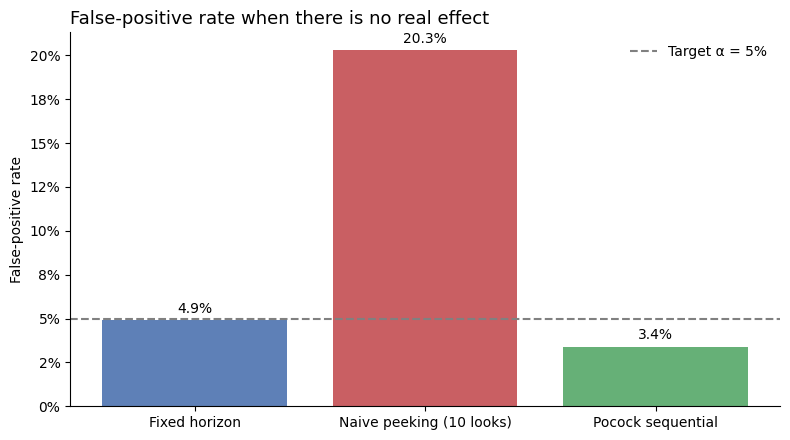

In [0]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#4C72B0", "#C44E52", "#55A868"]
bars = ax.bar(fpr.index, fpr.values, color=colors, alpha=0.9)

ax.axhline(0.05, color="grey", linestyle="--", linewidth=1.5, label="Target α = 5%")
ax.bar_label(bars, labels=[f"{v:.1%}" for v in fpr.values], padding=3)

ax.set_title("False-positive rate when there is no real effect", loc="left", fontsize=13)
ax.set_ylabel("False-positive rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

**Result:** Testing once at the end held the false-positive rate at **4.9%**. Peeking at 10 interim looks and stopping at the first p < 0.05 inflated it to **20.3%**, about 4× the intended rate. A Pocock boundary brought it back to **3.4%**.

**Takeaway:** if results will be monitored during an experiment, the stopping rule must be planned in advance with a sequential method. The Hillstrom test wasn't monitored over time, so this section demonstrates why the analysis uses a single fixed-horizon test.

## 8. Segment Analysis (Heterogeneous Treatment Effects)
Treatment effects on spend are estimated within segments of channel, zip code, and new vs. existing customers, for each email vs. control.

With 16 segment comparisons, ~1 would appear significant by chance alone at α = 0.05. p-values are therefore adjusted with **Benjamini-Hochberg**, controlling the false discovery rate at 5%.

Segment results are **exploratory**: they generate hypotheses for targeting, not ship decisions on their own.

In [0]:
from statsmodels.stats.multitest import multipletests

metric = "spend"   # swap to "visit" or "conversion" to compare
rows = []

for seg in ["channel", "zip_code", "newbie"]:
    for level in sorted(df[seg].unique()):
        sub = df[df[seg] == level]
        c = sub[sub["segment"] == "No E-Mail"][metric]

        for arm in ["Mens E-Mail", "Womens E-Mail"]:
            t = sub[sub["segment"] == arm][metric]
            res = ttest_ind(t, c, equal_var=False)
            ci = res.confidence_interval(confidence_level=0.95)

            rows.append({
                "segment": f"{seg} = {level}",
                "arm": arm,
                "n_per_arm": len(t),
                "lift": t.mean() - c.mean(),
                "ci_low": ci.low,
                "ci_high": ci.high,
                "p_value": res.pvalue,
            })

seg_results = pd.DataFrame(rows)

# Benjamini-Hochberg adjustment across all 16 tests
seg_results["significant_bh"], seg_results["p_adj_bh"], _, _ = multipletests(
    seg_results["p_value"], alpha=0.05, method="fdr_bh"
)

seg_results.round(4)

,segment,arm,n_per_arm,lift,ci_low,ci_high,p_value,significant_bh,p_adj_bh
0,channel = Multichannel,Mens E-Mail,2577,1.2091,0.3908,2.0274,0.0038,True,0.0087
1,channel = Multichannel,Womens E-Mail,2579,1.1575,0.2586,2.0565,0.0116,True,0.0186
2,channel = Phone,Mens E-Mail,9240,0.5641,0.1611,0.9670,0.0061,True,0.0122
3,channel = Phone,Womens E-Mail,9454,0.2325,-0.1192,0.5842,0.1951,False,0.2230
4,channel = Web,Mens E-Mail,9490,0.8504,0.3972,1.3037,0.0002,True,0.0013
5,channel = Web,Womens E-Mail,9354,0.4163,0.0245,0.8081,0.0373,True,0.0497
6,zip_code = Rural,Mens E-Mail,3243,0.7555,0.0508,1.4602,0.0356,True,0.0497
7,zip_code = Rural,Womens E-Mail,3181,0.5148,-0.1197,1.1494,0.1117,False,0.1375
8,zip_code = Surburban,Mens E-Mail,9501,0.8038,0.3541,1.2536,0.0005,True,0.0018
9,zip_code = Surburban,Womens E-Mail,9650,0.1772,-0.1936,0.5480,0.3490,False,0.3722


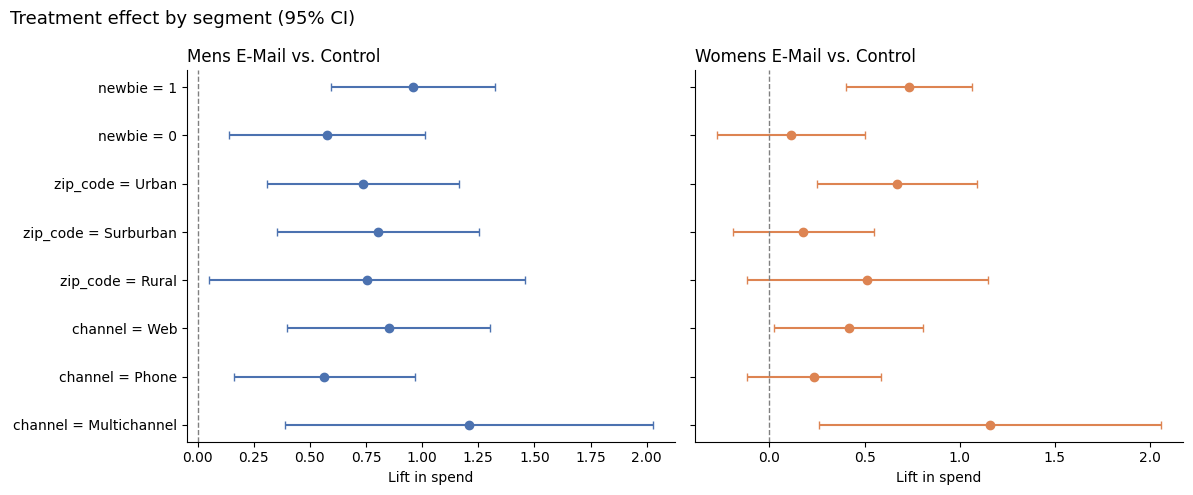

In [0]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, arm, color in zip(axes, ["Mens E-Mail", "Womens E-Mail"], ["#4C72B0", "#DD8452"]):
    r = seg_results[seg_results["arm"] == arm]
    ax.errorbar(r["lift"], r["segment"],
                xerr=[r["lift"] - r["ci_low"], r["ci_high"] - r["lift"]],
                fmt="o", color=color, capsize=3)
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(f"{arm} vs. Control", loc="left", fontsize=12)
    ax.set_xlabel(f"Lift in {metric}")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Treatment effect by segment (95% CI)", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

**Result:** 12 of 16 segment comparisons remain significant after Benjamini-Hochberg adjustment.
- **Men's email:** significant lift in **all 8 segments** (every channel, zip code, and new/existing customers).
- **Women's email:** significant for Multichannel, Web, Urban, and new customers; **not detectable** for Phone, Rural, Suburban, or existing customers.
- Both emails lifted spend more among **new customers** than existing ones, most visibly for the Women's email (~$0.73 vs. ~$0.11). Multichannel customers show the largest point estimates but also the widest CIs (smallest segment).

**Caveat:** segments split the sample into smaller groups with less power, so a non-significant segment doesn't mean "no effect." A significant effect in one segment and not another also doesn't prove the effects differ (that requires an interaction test). These are hypotheses for targeting, to be validated in a follow-up experiment.

### 8b. Head-to-Head: Men's vs. Women's Email
Both emails beat control, but choosing between them requires comparing them directly. Overlapping CIs vs. control don't settle that.

In [ ]:
mens   = df[df["segment"] == "Mens E-Mail"]
womens = df[df["segment"] == "Womens E-Mail"]

# Spend
res = ttest_ind(mens["spend"], womens["spend"], equal_var=False)
ci = res.confidence_interval(confidence_level=0.975)
print(f"Spend:  diff = ${mens['spend'].mean() - womens['spend'].mean():.3f}, "
      f"97.5% CI [{ci.low:.3f}, {ci.high:.3f}], p = {res.pvalue:.4f}")

# Visit and conversion
for m in ["visit", "conversion"]:
    _, p = proportions_ztest([mens[m].sum(), womens[m].sum()], [len(mens), len(womens)])
    print(f"{m.capitalize():11s} diff = {(mens[m].mean() - womens[m].mean()) * 100:.2f} pp, p = {p:.5f}")

Spend:  diff = $0.345, 97.5% CI [-0.012, 0.703], p = 0.0305
Visit       diff = 3.14 pp, p = 0.00000
Conversion  diff = 0.37 pp, p = 0.00021


**Result:** The Men's email drove significantly more visits (+3.14 pp, p < 0.001) and conversions (+0.37 pp, p < 0.001) than the Women's email. Its spend advantage (+$0.35, p = 0.031) is directionally consistent but **not significant** at α = 0.025, as the CI just crosses zero.

## 9. Decision Memo

### Recommendation: Ship the Men's email as the default re-engagement campaign

**Summary:** Both emails significantly increased visits, conversions, and spend vs. no email. Head-to-head, the Men's email drove **significantly more visits and conversions** than the Women's email, and **directionally higher spend** (not statistically conclusive). It was also the only version that worked consistently across every customer segment.

### Results (each email vs. no email, two-week window)
| Metric | Control | Men's email | Women's email |
|---|---|---|---|
| Spend per customer | $0.65 | **+$0.77 (+118%)**, 97.5% CI [$0.44, $1.10] | **+$0.42 (+65%)**, 97.5% CI [$0.13, $0.72] |
| Visit rate | 10.6% | **+7.7 pp (+72%)** | **+4.5 pp (+43%)** |
| Conversion rate | 0.57% | **+0.68 pp (+119%)** | **+0.31 pp (+54%)** |

All lifts significant at the Bonferroni-adjusted α = 0.025.

**Men's vs. Women's head-to-head:** spend difference of $0.35 (p = 0.031, not significant at α = 0.025); visit difference of 3.14 pp (p < 0.001); conversion difference of 0.37 pp (p < 0.001).

**Business impact:** at +$0.77 per customer vs. no email, every 10,000 customers emailed generates roughly **$7,700 in additional two-week revenue**, vs. ~$4,200 for the Women's email. The ~$3,500 gap between the two emails is a point estimate and isn't statistically confirmed.

### Why the results can be trusted
- **Randomization worked:** no sample ratio mismatch (χ² = 0.20, p = 0.90), and all pre-experiment covariates balanced (max |SMD| = 0.014, well under 0.1).
- **The test is well-calibrated:** A/A simulation gave a 4.9% false-positive rate at α = 0.05, despite 99.1% of customers having $0 spend.
- **Robust to skew:** bootstrap CIs matched Welch's t-test CIs almost exactly (Men's: [0.44, 1.09] vs. [0.44, 1.10]).
- **Adequately powered:** both spend lifts exceed the experiment's MDE of $0.35.

### Segment findings (exploratory, Benjamini-Hochberg adjusted)
- **Men's email:** significant lift in **all 8 segments** (every channel, zip code, and new/existing customers).
- **Women's email:** no detectable lift for Phone customers, Rural and Suburban customers, or existing (non-new) customers.
- Both emails lifted spend more among **new customers** than existing ones, most visibly for the Women's email (~$0.73 vs. ~$0.11). Multichannel customers show the largest point estimates but also the widest CIs (smallest segment).

### Methodology notes
- **CUPED gave no variance reduction** (ρ = 0.02 between past-year spend and two-week spend). Pre-period spend doesn't predict purchases in a short two-week window, so CUPED wasn't applicable to this metric. It is expected to help more on metrics with stronger pre-period correlation.
- **A single fixed-horizon test was used.** Simulation showed that peeking at 10 interim looks would have inflated the false-positive rate from 4.9% to 20.3%, while a Pocock sequential boundary kept it at 3.4%.

### Risks and limitations
- **No guardrail metric:** unsubscribe and complaint rates weren't recorded, so the cost of email fatigue is unknown.
- **Revenue, not profit:** spend excludes margin, email costs, and returns.
- **Short window:** only two weeks of outcomes, so long-term retention effects and possible pull-forward of purchases are unmeasured.
- **Segment results are exploratory:** they suggest targeting ideas but weren't the primary test.

### Next steps
1. Roll out the Men's email, keeping a **small holdout group** to track unsubscribes and longer-term revenue.
2. Run a follow-up test of whether the Women's email outperforms the Men's for **customers who previously bought women's merchandise**, a targeting idea this experiment wasn't designed to answer.
3. Extend the outcome window to 30–60 days to check whether the lift persists or is just pulled-forward demand.